# Règles d'association : Apriori, FP-Growth et sélection des règles intéressantes

*TP1 « Extraction de règles d'association, l'algorithme Apriori » · Théorie de l'Apprentissage Symbolique · INFO2*

---

### Résumé
Ce notebook traite le TP Apriori puis va plus loin, avec une **analyse comparative** et des **choix argumentés** :

1. **Panier de courses** (`GroceryStoreDataSet.csv`, 20 transactions) : encodage, itemsets fréquents, règles, filtres pour l'expert (questions 3 à 7 du sujet).
2. Une **implémentation d'Apriori écrite à la main**, comparée à celle de mlxtend.
3. Une **étude de sensibilité** au support minimal et à la confiance, et le choix argumenté des seuils.
4. Une **comparaison des mesures d'intérêt** (confiance, lift, leverage, conviction, Zhang) : pourquoi la confiance seule trompe.
5. Une **comparaison des algorithmes** : Apriori, FP-Growth, FP-Max (itemsets maximaux) et itemsets fermés.
6. Les **propriétés théoriques** (questions 8 et 9 du sujet), démontrées puis vérifiées sur les données.
7. Le **passage à l'échelle sur des données réelles** (`medspe.tsv`, 493 étudiants en médecine) : choix de spécialité, biais de genre et élagage des règles redondantes.

### Sommaire
1. [Données et encodage](#1)
2. [Itemsets fréquents (min-support 0,2)](#2)
3. [Apriori écrit à la main](#3)
4. [Règles d'association (confiance > 0,6)](#4)
5. [Aider l'expert à sélectionner les règles](#5)
6. [Choix des seuils : sensibilité](#6)
7. [Comparaison des mesures d'intérêt](#7)
8. [Comparaison des algorithmes](#8)
9. [Questions théoriques 8 et 9](#9)
10. [Données réelles : medspe](#10)
11. [Conclusion](#11)

In [1]:
import importlib.util
if importlib.util.find_spec("mlxtend") is None:
    %pip install -q mlxtend

In [2]:
import os, time, itertools, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, fpmax, association_rules

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
fmt = lambda fs: "{" + ", ".join(sorted(fs)) + "}"   # affichage lisible d'un frozenset

def find_file(name):
    # Cherche le fichier dans le dossier courant ou le dossier parent (pour Colab : uploader le fichier)
    for p in [name, os.path.join("..", name), os.path.join("data", name)]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} introuvable : placez-le à côté du notebook (sur Colab : panneau Fichiers > Importer)")

<a id="1"></a>
## 1. Données et encodage (questions 3 et 4)

In [3]:
raw = pd.read_csv(find_file("GroceryStoreDataSet.csv"), header=None, names=["transaction"])
display(raw.head(2))
dataset = [t.split(",") for t in raw["transaction"]]
print(f"{len(dataset)} transactions ; deux premières :", dataset[:2])

,transaction
0,"MILK,BREAD,BISCUIT"
1,"BREAD,MILK,BISCUIT,CORNFLAKES"


20 transactions ; deux premières : [['MILK', 'BREAD', 'BISCUIT'], ['BREAD', 'MILK', 'BISCUIT', 'CORNFLAKES']]


,BISCUIT,BOURNVITA,BREAD,COCK,COFFEE,CORNFLAKES,JAM,MAGGI,MILK,SUGER,TEA
0,True,False,True,False,False,False,False,False,True,False,False
1,True,False,True,False,False,True,False,False,True,False,False
2,False,True,True,False,False,False,False,False,False,False,True
3,False,False,True,False,False,False,True,True,True,False,False
4,True,False,False,False,False,False,False,True,False,False,True


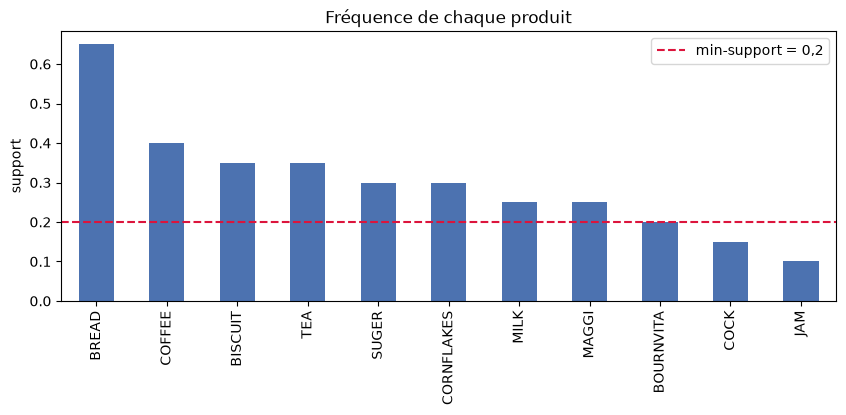

Taille moyenne d'un panier : 3.30 produits ; 11 produits distincts


In [4]:
te = TransactionEncoder()
df = pd.DataFrame(te.fit(dataset).transform(dataset), columns=te.columns_)
display(df.head())

freq = df.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.5))
freq.plot.bar(ax=ax, color="#4C72B0"); ax.axhline(0.2, color="crimson", ls="--", label="min-support = 0,2")
ax.set_ylabel("support"); ax.set_title("Fréquence de chaque produit"); ax.legend(); plt.show()
print(f"Taille moyenne d'un panier : {df.sum(axis=1).mean():.2f} produits ; {df.shape[1]} produits distincts")

`TransactionEncoder` produit une matrice booléenne transactions × produits, c'est-à-dire une représentation « one-hot » des paniers.

Le pain (`BREAD`) est dans 65 % des paniers : il **dominera** les règles. Il faudra s'en méfier, car une règle `X → BREAD` aura une confiance élevée même si `X` n'a aucun lien avec le pain. Deux produits (`COCK`, `JAM`) sont sous le seuil de 0,2 et ne pourront apparaître dans aucun itemset fréquent (anti-monotonie du support).

<a id="2"></a>
## 2. Itemsets fréquents (question 5)

In [5]:
fi = apriori(df, min_support=0.2, use_colnames=True)
fi["taille"] = fi["itemsets"].apply(len)
fi.sort_values(["taille", "support"], ascending=[True, False]).assign(itemsets=lambda d: d.itemsets.apply(fmt))

,support,itemsets,taille
2,0.65,{BREAD},1
3,0.40,{COFFEE},1
0,0.35,{BISCUIT},1
8,0.35,{TEA},1
4,0.30,{CORNFLAKES},1
7,0.30,{SUGER},1
5,0.25,{MAGGI},1
6,0.25,{MILK},1
1,0.20,{BOURNVITA},1
9,0.20,"{BISCUIT, BREAD}",2


Avec un support minimal de 0,2, on obtient **16 itemsets fréquents** : 9 singletons et 7 paires, mais **aucun triplet**. Avec seulement 20 paniers, un triplet devrait apparaître dans au moins 4 transactions, ce qui n'arrive jamais.

<a id="3"></a>
## 3. Apriori écrit à la main

Pour bien comprendre l'algorithme, on l'implémente nous-mêmes puis on compare le résultat à mlxtend :
- **génération** des candidats de taille $k+1$ par jointure des itemsets fréquents de taille $k$ ;
- **élagage** : un candidat dont un sous-ensemble de taille $k$ n'est pas fréquent est rejeté sans compter son support. C'est la propriété d'**anti-monotonie** ;
- **comptage** du support des candidats restants.

In [6]:
def apriori_scratch(transactions, min_support):
    n = len(transactions)
    T = [frozenset(t) for t in transactions]
    counts = Counter(i for t in T for i in t)
    Lk = {frozenset([i]): c / n for i, c in counts.items() if c / n >= min_support}
    result, stats = dict(Lk), []
    k = 1
    while Lk:
        prev = list(Lk)
        # jointure : union de deux itemsets de taille k qui donne un itemset de taille k+1
        candidates = {a | b for a, b in itertools.combinations(prev, 2) if len(a | b) == k + 1}
        # élagage a priori : tous les sous-ensembles de taille k doivent être fréquents
        pruned = {c for c in candidates if all(frozenset(s) in Lk for s in itertools.combinations(c, k))}
        sup = {c: sum(c <= t for t in T) / n for c in pruned}
        Lk = {c: s for c, s in sup.items() if s >= min_support}
        stats.append(dict(k=k + 1, candidats=len(candidates), apres_elagage=len(pruned), frequents=len(Lk)))
        result.update(Lk); k += 1
    return result, pd.DataFrame(stats)

for s in [0.2, 0.1, 0.05]:
    mine, stats = apriori_scratch(dataset, s)
    ref = apriori(df, min_support=s, use_colnames=True)
    same = {fs: round(v, 10) for fs, v in mine.items()} == {fs: round(v, 10) for fs, v in zip(ref.itemsets, ref.support)}
    print(f"min_support={s:<5} : {len(mine):3d} itemsets — identique à mlxtend : {same}")
print("\nEffet de l'élagage (min_support = 0,05) :")
apriori_scratch(dataset, 0.05)[1]

min_support=0.2   :  16 itemsets — identique à mlxtend : True
min_support=0.1   :  46 itemsets — identique à mlxtend : True
min_support=0.05  :  83 itemsets — identique à mlxtend : True

Effet de l'élagage (min_support = 0,05) :


,k,candidats,apres_elagage,frequents
0,2,55,55,36
1,3,115,53,30
2,4,54,6,6
3,5,2,0,0


L'implémentation donne **exactement** les mêmes itemsets et supports que mlxtend. Le tableau montre l'intérêt de l'élagage : une partie des candidats est éliminée **sans parcourir la base**, simplement parce qu'un de leurs sous-ensembles n'est pas fréquent.

<a id="4"></a>
## 4. Règles d'association (question 6)

Pour une règle $X \to Y$ :
- $\text{supp}(X\to Y) = P(X \cup Y)$ ;
- $\text{conf} = P(Y \mid X)$ ;
- $\text{lift} = \dfrac{\text{conf}}{P(Y)}$. Un lift supérieur à 1 indique une association positive, un lift égal à 1 l'indépendance.

In [7]:
rules = association_rules(fi, metric="confidence", min_threshold=0.6)
def view(r, cols=("antecedents", "consequents", "support", "confidence", "lift")):
    out = r[list(cols)].copy()
    out["antecedents"] = out["antecedents"].apply(fmt); out["consequents"] = out["consequents"].apply(fmt)
    return out.round(3).reset_index(drop=True)
view(rules.sort_values("lift", ascending=False))

,antecedents,consequents,support,confidence,lift
0,{MAGGI},{TEA},0.2,0.800,2.286
1,{SUGER},{COFFEE},0.2,0.667,1.667
2,{CORNFLAKES},{COFFEE},0.2,0.667,1.667
3,{MILK},{BREAD},0.2,0.800,1.231
4,{SUGER},{BREAD},0.2,0.667,1.026


On obtient 5 règles. Le cas de `SUGER → BREAD` est instructif : sa confiance de 0,67 semble bonne, mais son **lift vaut 1,03**. Acheter du sucre n'augmente presque pas la probabilité d'acheter du pain, déjà de 65 %. La règle est **sans intérêt** malgré sa confiance, conformément à la mise en garde de la partie 1.

À l'inverse, `MAGGI → TEA` a un lift de 2,29 : la probabilité d'acheter du thé est plus que doublée quand on achète des nouilles Maggi (80 % contre 35 %).

<a id="5"></a>
## 5. Aider l'expert à sélectionner les règles (question 7)

Avec seulement 5 règles au seuil de 0,2, plusieurs filtres demandés (règles sûres, plus de deux antécédents) donnent un résultat **vide**. On construit donc un catalogue plus riche avec un **support de 0,1** (au moins 2 paniers), qu'on filtre ensuite. La partie 6 justifie ce choix.

In [8]:
fi10 = apriori(df, min_support=0.1, use_colnames=True)
rules10 = association_rules(fi10, metric="confidence", min_threshold=0.6)
print(f"min_support=0,2 → {len(rules)} règles ; min_support=0,1 → {len(rules10)} règles")

# a) ne garder que support, confiance et lift
print("\n(a) Mesures support / confiance / lift (10 meilleures par lift)")
display(view(rules10.sort_values("lift", ascending=False)).head(10))

min_support=0,2 → 5 règles ; min_support=0,1 → 46 règles

(a) Mesures support / confiance / lift (10 meilleures par lift)


,antecedents,consequents,support,confidence,lift
0,"{BISCUIT, COFFEE}","{COCK, CORNFLAKES}",0.1,1.000,10.000
1,"{COCK, CORNFLAKES}","{BISCUIT, COFFEE}",0.1,1.000,10.000
2,"{BREAD, MAGGI}",{JAM},0.1,0.667,6.667
3,{COCK},"{BISCUIT, COFFEE}",0.1,0.667,6.667
4,"{BISCUIT, COFFEE}",{COCK},0.1,1.000,6.667
5,"{BISCUIT, COFFEE, CORNFLAKES}",{COCK},0.1,1.000,6.667
6,{JAM},"{BREAD, MAGGI}",0.1,1.000,6.667
7,{COCK},"{BISCUIT, COFFEE, CORNFLAKES}",0.1,0.667,6.667
8,"{BISCUIT, COCK}","{COFFEE, CORNFLAKES}",0.1,1.000,5.000
9,"{BISCUIT, CORNFLAKES}","{COCK, COFFEE}",0.1,0.667,4.444


In [9]:
def select(r, title, mask):
    sub = r[mask].sort_values(["lift", "support"], ascending=False)
    print(f"{title} : {len(sub)} règle(s)")
    display(view(sub).head(12))

select(rules10, "(b) Règles sûres (confiance = 1), quel que soit le support ≥ 0,1", rules10.confidence == 1)
select(rules10, "(c) Lift > 1,2 et confiance > 0,7", (rules10.lift > 1.2) & (rules10.confidence > 0.7))
select(rules10, "(d) Règles contenant BREAD (antécédent ou conséquent)",
       rules10.apply(lambda r: "BREAD" in r.antecedents | r.consequents, axis=1))
select(rules10, "(e) Règles avec au moins deux antécédents", rules10.antecedents.apply(len) >= 2)

(b) Règles sûres (confiance = 1), quel que soit le support ≥ 0,1 : 23 règle(s)


,antecedents,consequents,support,confidence,lift
0,"{COCK, CORNFLAKES}","{BISCUIT, COFFEE}",0.1,1.0,10.000
1,"{BISCUIT, COFFEE}","{COCK, CORNFLAKES}",0.1,1.0,10.000
2,"{BISCUIT, COFFEE}",{COCK},0.1,1.0,6.667
3,{JAM},"{BREAD, MAGGI}",0.1,1.0,6.667
4,"{BISCUIT, COFFEE, CORNFLAKES}",{COCK},0.1,1.0,6.667
5,"{BISCUIT, COCK}","{COFFEE, CORNFLAKES}",0.1,1.0,5.000
6,{JAM},{MAGGI},0.1,1.0,4.000
7,"{BISCUIT, TEA}",{MAGGI},0.1,1.0,4.000
8,"{BREAD, JAM}",{MAGGI},0.1,1.0,4.000
9,"{BISCUIT, COCK}",{CORNFLAKES},0.1,1.0,3.333


(c) Lift > 1,2 et confiance > 0,7 : 25 règle(s)


,antecedents,consequents,support,confidence,lift
0,"{COCK, CORNFLAKES}","{BISCUIT, COFFEE}",0.1,1.0,10.000
1,"{BISCUIT, COFFEE}","{COCK, CORNFLAKES}",0.1,1.0,10.000
2,"{BISCUIT, COFFEE}",{COCK},0.1,1.0,6.667
3,{JAM},"{BREAD, MAGGI}",0.1,1.0,6.667
4,"{BISCUIT, COFFEE, CORNFLAKES}",{COCK},0.1,1.0,6.667
5,"{BISCUIT, COCK}","{COFFEE, CORNFLAKES}",0.1,1.0,5.000
6,{JAM},{MAGGI},0.1,1.0,4.000
7,"{BISCUIT, TEA}",{MAGGI},0.1,1.0,4.000
8,"{BREAD, JAM}",{MAGGI},0.1,1.0,4.000
9,"{BISCUIT, COCK}",{CORNFLAKES},0.1,1.0,3.333


(d) Règles contenant BREAD (antécédent ou conséquent) : 14 règle(s)


,antecedents,consequents,support,confidence,lift
0,"{BREAD, MAGGI}",{JAM},0.10,0.667,6.667
1,{JAM},"{BREAD, MAGGI}",0.10,1.000,6.667
2,"{BREAD, JAM}",{MAGGI},0.10,1.000,4.000
3,"{BREAD, COFFEE}",{SUGER},0.10,0.667,2.222
4,"{BOURNVITA, BREAD}",{TEA},0.10,0.667,1.905
5,"{BREAD, MAGGI}",{TEA},0.10,0.667,1.905
6,{JAM},{BREAD},0.10,1.000,1.538
7,"{BISCUIT, MILK}",{BREAD},0.10,1.000,1.538
8,"{BOURNVITA, TEA}",{BREAD},0.10,1.000,1.538
9,"{JAM, MAGGI}",{BREAD},0.10,1.000,1.538


(e) Règles avec au moins deux antécédents : 29 règle(s)


,antecedents,consequents,support,confidence,lift
0,"{COCK, CORNFLAKES}","{BISCUIT, COFFEE}",0.1,1.000,10.000
1,"{BISCUIT, COFFEE}","{COCK, CORNFLAKES}",0.1,1.000,10.000
2,"{BISCUIT, COFFEE}",{COCK},0.1,1.000,6.667
3,"{BREAD, MAGGI}",{JAM},0.1,0.667,6.667
4,"{BISCUIT, COFFEE, CORNFLAKES}",{COCK},0.1,1.000,6.667
5,"{BISCUIT, COCK}","{COFFEE, CORNFLAKES}",0.1,1.000,5.000
6,"{BISCUIT, CORNFLAKES}",{COCK},0.1,0.667,4.444
7,"{BISCUIT, CORNFLAKES}","{COCK, COFFEE}",0.1,0.667,4.444
8,"{COCK, COFFEE}","{BISCUIT, CORNFLAKES}",0.1,0.667,4.444
9,"{BISCUIT, TEA}",{MAGGI},0.1,1.000,4.000


In [10]:
# (e bis) « plus de deux » au sens strict (≥ 3 antécédents) exige un support plus bas
fi05 = apriori(df, min_support=0.05, use_colnames=True)
rules05 = association_rules(fi05, metric="confidence", min_threshold=0.6)
select(rules05, "(e) Règles avec plus de deux antécédents (≥ 3), min_support = 0,05", rules05.antecedents.apply(len) >= 3)

(e) Règles avec plus de deux antécédents (≥ 3), min_support = 0,05 : 18 règle(s)


,antecedents,consequents,support,confidence,lift
0,"{BREAD, MAGGI, MILK}",{JAM},0.05,1.0,10.000
1,"{BISCUIT, COFFEE, CORNFLAKES}",{COCK},0.10,1.0,6.667
2,"{BISCUIT, BREAD, CORNFLAKES}",{MILK},0.05,1.0,4.000
3,"{BISCUIT, BREAD, TEA}",{MAGGI},0.05,1.0,4.000
4,"{BREAD, JAM, MILK}",{MAGGI},0.05,1.0,4.000
5,"{BREAD, JAM, TEA}",{MAGGI},0.05,1.0,4.000
6,"{COFFEE, CORNFLAKES, TEA}",{MILK},0.05,1.0,4.000
7,"{BISCUIT, COCK, COFFEE}",{CORNFLAKES},0.10,1.0,3.333
8,"{COFFEE, MILK, TEA}",{CORNFLAKES},0.05,1.0,3.333
9,"{COCK, COFFEE, CORNFLAKES}",{BISCUIT},0.10,1.0,2.857


**Commentaires pour l'expert.**
- **(b) Règles sûres** : elles ont toutes une confiance de 100 %, mais leur support est de 0,1, soit 2 paniers. Sur 20 transactions, « sûr » veut dire « vrai sur 2 cas ». La certitude est **statistiquement fragile**, et ces règles doivent être confirmées sur plus de données.
- **(c) Lift > 1,2 et confiance > 0,7** : c'est le filtre le plus utile. Il retient des associations à la fois fiables et non triviales.
- **(d) Filtrer sur un item** répond à une question métier, par exemple « que vendre avec le pain ? ». Comme `BREAD` est très fréquent, les règles `… → BREAD` ont naturellement un lift proche de 1, et il vaut mieux regarder les règles `BREAD → …`.
- **(e) Plusieurs antécédents** : les règles longues sont plus spécifiques et ont mécaniquement un support plus faible. Avec plus de deux antécédents, il faut descendre à 0,05, c'est-à-dire **une seule transaction** : ces règles ne sont alors que la description d'un panier particulier (sur-apprentissage).

<a id="6"></a>
## 6. Choix des seuils : sensibilité au support et à la confiance

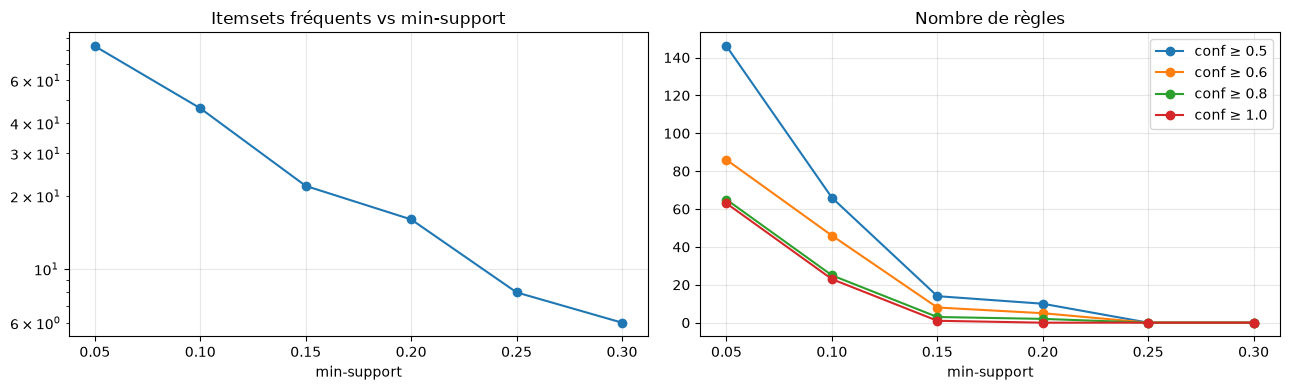

min_conf,0.5,0.6,0.7,0.8,0.9,1.0
min_support,,,,,,
0.05,146,86,66,65,63,63
0.10,66,46,26,25,23,23
0.15,14,8,4,3,1,1
0.20,10,5,2,2,0,0
0.25,0,0,0,0,0,0
0.30,0,0,0,0,0,0


In [11]:
grid = []
for s in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3]:
    f = apriori(df, min_support=s, use_colnames=True)
    for c in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
        r = association_rules(f, metric="confidence", min_threshold=c) if len(f) else pd.DataFrame(columns=["lift"])
        grid.append(dict(min_support=s, min_conf=c, n_itemsets=len(f), n_rules=len(r),
                         n_rules_lift_gt_1=int((r["lift"] > 1).sum()) if len(r) else 0))
grid = pd.DataFrame(grid)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
g = grid.drop_duplicates("min_support")
axes[0].plot(g.min_support, g.n_itemsets, "o-"); axes[0].set_title("Itemsets fréquents vs min-support")
axes[0].set_xlabel("min-support"); axes[0].set_yscale("log")
for c in [0.5, 0.6, 0.8, 1.0]:
    sub = grid[grid.min_conf == c]; axes[1].plot(sub.min_support, sub.n_rules, "o-", label=f"conf ≥ {c}")
axes[1].set_title("Nombre de règles"); axes[1].set_xlabel("min-support"); axes[1].legend()
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
grid.pivot(index="min_support", columns="min_conf", values="n_rules")

**Analyse et choix.** Le nombre d'itemsets décroît **exponentiellement** avec le support minimal (l'axe est logarithmique).
- Pour **0,25 et plus**, il ne reste aucune règle de confiance ≥ 0,6 : le seuil est trop strict.
- Pour **0,05**, on obtient plus de 80 règles, dont une grande partie ne repose que sur **un seul panier**. C'est du bruit.
- **0,1** (au moins 2 paniers) est le compromis retenu pour l'exploration. **0,2** (au moins 4 paniers) convient si l'on veut présenter uniquement des règles robustes.

Le seuil de confiance a moins d'effet que le support. Il vaut mieux le fixer modéré (0,6 à 0,7) et **filtrer ensuite par le lift**, qui écarte les règles qui ne font qu'exploiter un conséquent fréquent.

<a id="7"></a>
## 7. Comparaison des mesures d'intérêt

On compare cinq mesures :
- la **confiance** $P(Y\mid X)$ ;
- le **lift** $P(Y\mid X)/P(Y)$ ;
- le **leverage** $P(XY)-P(X)P(Y)$ ;
- la **conviction** $\frac{1-P(Y)}{1-\text{conf}}$, qui vaut $+\infty$ pour une règle sûre ;
- la **métrique de Zhang**, comprise dans $[-1,1]$.

On regarde si elles **classent les règles de la même façon**.

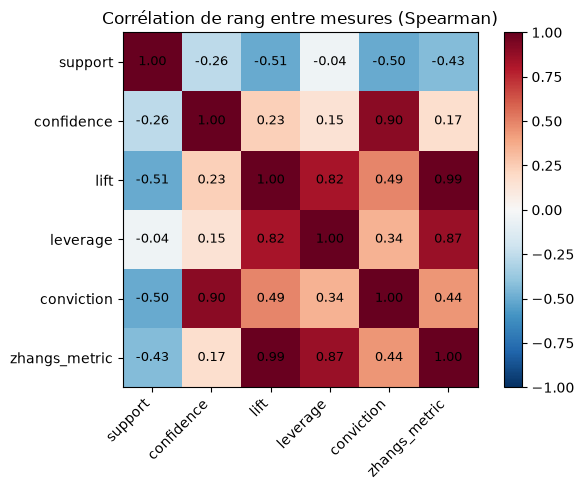

Recouvrement du top 10 : confiance ∩ lift = 1 | lift ∩ leverage = 8 | lift ∩ zhang = 9


In [12]:
M = rules10[["support", "confidence", "lift", "leverage", "conviction", "zhangs_metric"]].replace(np.inf, np.nan)
M["conviction"] = M["conviction"].fillna(M["conviction"].max() * 1.5)   # règles sûres : conviction infinie
corr = M.rank().corr()   # corrélation de Spearman = corrélation des rangs
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im); ax.set_title("Corrélation de rang entre mesures (Spearman)"); plt.tight_layout(); plt.show()

top = lambda col: set(rules10.assign(k=M[col]).nlargest(10, "k").index)
print("Recouvrement du top 10 : confiance ∩ lift =", len(top("confidence") & top("lift")),
      "| lift ∩ leverage =", len(top("lift") & top("leverage")), "| lift ∩ zhang =", len(top("lift") & top("zhangs_metric")))

In [13]:
# Règles à forte confiance mais lift ≤ 1 : les « faux amis »
trap = rules10[(rules10.confidence >= 0.6) & (rules10.lift <= 1.05)]
print(f"{len(trap)} règle(s) de confiance ≥ 0,6 avec un lift ≤ 1,05 (quasi-indépendance) :")
view(trap)

2 règle(s) de confiance ≥ 0,6 avec un lift ≤ 1,05 (quasi-indépendance) :


,antecedents,consequents,support,confidence,lift
0,{MAGGI},{BREAD},0.15,0.600,0.923
1,{SUGER},{BREAD},0.20,0.667,1.026


**Conclusions sur les mesures.**
- **Confiance et lift ne classent pas les règles de la même façon** : leurs top 10 n'ont qu'**une** règle en commun. La confiance favorise les conséquents fréquents comme `BREAD`, alors que le lift les corrige. Les « faux amis » ci-dessus en sont l'illustration : `MAGGI → BREAD` a une confiance de 0,6 mais un lift de 0,92, ce qui indique une association **négative**. Acheter des Maggi rend l'achat de pain *moins* probable que la moyenne.
- **Lift, conviction et Zhang** mesurent tous l'écart à l'indépendance et sont très corrélés. Le **lift** est symétrique et facile à expliquer (« × 2,9 ») ; la **conviction** est orientée, mais devient infinie pour les règles sûres ; la métrique de **Zhang** est bornée et robuste.
- Le **leverage**, une différence absolue, favorise les règles à fort support : c'est une bonne mesure de **l'impact** d'une règle.
- **Choix retenu** pour présenter les règles à un expert : un filtre sur le support (pour la robustesse), un filtre sur la confiance (pour la fiabilité), puis un **tri par lift**, avec le leverage comme second critère pour départager à lift égal les règles qui concernent le plus de clients.

<a id="8"></a>
## 8. Comparaison des algorithmes

- **Apriori** procède niveau par niveau (génération, élagage, comptage) et parcourt la base une fois par niveau.
- **FP-Growth** compresse la base dans un arbre préfixe (FP-tree) et extrait les motifs **sans générer de candidats**.
- **FP-Max** ne renvoie que les itemsets **maximaux**, c'est-à-dire les fréquents dont aucun sur-ensemble n'est fréquent.
- Les itemsets **fermés** sont ceux dont aucun sur-ensemble n'a le **même** support. Ils forment une représentation **sans perte** : on peut retrouver le support de n'importe quel itemset fréquent à partir d'eux.

In [14]:
def closed_itemsets(fi_df):
    sup = dict(zip(fi_df.itemsets, fi_df.support))
    return [s for s in sup if not any(s < t and abs(sup[t] - sup[s]) < 1e-12 for t in sup)]

rows = []
for s in [0.05, 0.1, 0.2]:
    a = apriori(df, min_support=s, use_colnames=True); b = fpgrowth(df, min_support=s, use_colnames=True)
    mx = fpmax(df, min_support=s, use_colnames=True)
    same = set(zip(a.itemsets, a.support.round(10))) == set(zip(b.itemsets, b.support.round(10)))
    rows.append(dict(min_support=s, apriori=len(a), fpgrowth=len(b), identiques=same,
                     fermés=len(closed_itemsets(a)), maximaux=len(mx)))
pd.DataFrame(rows)

,min_support,apriori,fpgrowth,identiques,fermés,maximaux
0,0.05,83,83,True,42,14
1,0.10,46,46,True,31,10
2,0.20,16,16,True,16,8


Apriori et FP-Growth donnent **exactement** le même résultat : ce sont deux algorithmes exacts. Les itemsets fermés et surtout maximaux en sont des **résumés compacts**. On a toujours maximaux ⊆ fermés ⊆ fréquents. Les maximaux suffisent à savoir *quels* itemsets sont fréquents, mais pas à retrouver leurs supports ; les fermés, eux, conservent toute l'information.

Sur 20 transactions, les temps de calcul sont négligeables. La comparaison des temps est faite en partie 10, sur des données plus grandes.

<a id="9"></a>
## 9. Questions théoriques

### Question 8 — Si $X \to Y$ a un support $s$ et une confiance $c$, et si $X \subset Z$, que dire de $Z \to Y$ ($s'$, $c'$) ?

- **Support** : $X \cup Y \subseteq Z \cup Y$, donc toute transaction qui contient $Z\cup Y$ contient aussi $X\cup Y$. Par **anti-monotonie** :
  $$s' = \text{supp}(Z\cup Y) \le \text{supp}(X\cup Y) = s.$$
- **Confiance** : $c' = \dfrac{\text{supp}(Z\cup Y)}{\text{supp}(Z)}$. Le numérateur **et** le dénominateur diminuent quand on spécialise l'antécédent : **on ne peut rien conclure en général**, et $c'$ peut être plus grande ou plus petite que $c$. Spécialiser l'antécédent peut aussi bien renforcer une règle (en ciblant un sous-groupe) que l'affaiblir.
- **Cas particulier utile** : si l'itemset total est fixé et qu'on déplace des items du conséquent vers l'antécédent, la confiance ne peut qu'augmenter : $\text{conf}(X \to Y\cup W) \le \text{conf}(X\cup W \to Y)$, car le numérateur est le même et le dénominateur diminue. C'est la propriété qu'utilise la génération des règles d'Apriori.

Vérification sur les données : on énumère tous les couples ($X\to Y$, $Z\to Y$) avec $X \subset Z$.

In [15]:
fi_all = apriori(df, min_support=0.05, use_colnames=True)
S = dict(zip(fi_all.itemsets, fi_all.support))
supp = lambda s: S.get(frozenset(s), 0.0)
items = sorted(df.columns)
viol_s, up, down, n = 0, [], [], 0
for XY in [k for k in S if len(k) >= 2]:
    for y in XY:
        Y = frozenset([y]); X = XY - Y
        s, c = supp(X | Y), supp(X | Y) / supp(X)
        for z in items:
            Z = X | {z}
            if z in XY or supp(Z) == 0 or supp(Z | Y) == 0:
                continue
            s2, c2 = supp(Z | Y), supp(Z | Y) / supp(Z); n += 1
            viol_s += s2 > s + 1e-12
            (up if c2 > c + 1e-12 else down if c2 < c - 1e-12 else []).append((fmt(X), fmt(Z), y, round(c, 2), round(c2, 2)))
print(f"{n} couples (X→Y, Z→Y) avec X ⊂ Z examinés")
print(f"  s' > s observé : {viol_s} fois (attendu : 0, anti-monotonie)")
print(f"  c' > c : {len(up)} fois, par ex. {up[:2]}")
print(f"  c' < c : {len(down)} fois, par ex. {down[:2]}")

252 couples (X→Y, Z→Y) avec X ⊂ Z examinés
  s' > s observé : 0 fois (attendu : 0, anti-monotonie)
  c' > c : 154 fois, par ex. [('{BISCUIT}', '{BISCUIT, MILK}', 'BREAD', 0.57, 1.0), ('{BISCUIT}', '{BISCUIT, SUGER}', 'BREAD', 0.57, 1.0)]
  c' < c : 42 fois, par ex. [('{BISCUIT}', '{BISCUIT, CORNFLAKES}', 'BREAD', 0.57, 0.33), ('{BISCUIT}', '{BISCUIT, MAGGI}', 'BREAD', 0.57, 0.5)]


### Question 9 — Que dire des règles $X \to Y$ et $X \cup \{a\} \to Y \cup \{a\}$ ?

Avec $a \notin X\cup Y$ :
- **Support** : $\text{supp}(X\cup Y\cup\{a\}) \le \text{supp}(X\cup Y)$, donc $s' \le s$ (anti-monotonie).
- **Confiance** :
  $$c' = \frac{\text{supp}(X\cup\{a\}\cup Y\cup\{a\})}{\text{supp}(X\cup\{a\})} = \frac{\text{supp}(X\cup\{a\}\cup Y)}{\text{supp}(X\cup\{a\})} = \text{conf}(X\cup\{a\} \to Y).$$
  Ajouter $a$ **des deux côtés** revient exactement à ajouter $a$ à l'antécédent seulement : l'item $a$ du conséquent est **trivialement vrai**, puisqu'il est déjà dans l'antécédent. On se ramène à la question 8 : aucune relation générale entre $c'$ et $c$.
- **Conséquence** : la règle $X\cup\{a\}\to Y\cup\{a\}$ est **redondante**, car elle n'apporte aucune information de plus que $X\cup\{a\}\to Y$. C'est pourquoi les algorithmes imposent $X \cap Y = \emptyset$. Si $a \in X$, les deux règles ont même support et même confiance : elles sont équivalentes.
- **Le lift change**, en revanche, puisque $P(Y\cup\{a\}) \ne P(Y)$. C'est un exemple où le lift « récompense » artificiellement une règle triviale, d'où l'intérêt de la contrainte $X\cap Y=\emptyset$.

In [16]:
checks = []
for XY in [k for k in S if len(k) >= 2]:
    for y in XY:
        Y = frozenset([y]); X = XY - Y
        for a in items:
            if a in XY or supp(X | {a}) == 0:
                continue
            c_both = supp(X | Y | {a}) / supp(X | {a})            # conf(X∪{a} → Y∪{a})
            c_ante = supp(X | {a} | Y) / supp(X | {a})            # conf(X∪{a} → Y)
            checks.append(dict(regle=f"{fmt(X)}→{y}", a=a, s=supp(XY), s_prime=supp(XY | {a}),
                               conf_XY=supp(XY) / supp(X), conf_both=c_both, conf_ante=c_ante))
ck = pd.DataFrame(checks)
print(f"{len(ck)} cas : s' ≤ s toujours : {(ck.s_prime <= ck.s + 1e-12).all()} ; "
      f"conf(X∪a → Y∪a) == conf(X∪a → Y) toujours : {np.allclose(ck.conf_both, ck.conf_ante)}")
print(f"c' > c dans {(ck.conf_both > ck.conf_XY + 1e-12).sum()} cas, c' < c dans {(ck.conf_both < ck.conf_XY - 1e-12).sum()} cas")

626 cas : s' ≤ s toujours : True ; conf(X∪a → Y∪a) == conf(X∪a → Y) toujours : True
c' > c dans 154 cas, c' < c dans 416 cas


<a id="10"></a>
## 10. Données réelles : `medspe` (étudiants en médecine)

`medspe.tsv` (le même fichier que le TP AMIE3) décrit **493 étudiants en médecine** sous forme de triplets `(sujet, prédicat, objet)` :
- leur sexe ;
- la réussite de la 1re année, en une fois (`Reussit`) ou en redoublant (`Double`) ;
- s'ils ont des parents médecins ;
- leur classement attendu à l'ECNi, en quartiles ;
- l'importance accordée à 6 facteurs dans le choix de spécialité (gardes, recherche, patients, précarité, actes techniques, soins spécialisés), notée de 1 à 5 ;
- la spécialité préférée (`généraliste` ou `autre`).

On transforme chaque étudiant en **transaction** d'items `attribut=valeur`. La relation `ami_de` relie deux étudiants : elle n'a pas de sens dans un panier et on l'ignore.

In [17]:
triples = pd.read_csv(find_file("medspe.tsv"), sep="\t")
attrs = triples[triples.predicat != "ami_de"]
med = attrs.assign(item=attrs.predicat + "=" + attrs.objet.astype(str)).groupby("sujet")["item"].apply(list)
te_m = TransactionEncoder()
dfm = pd.DataFrame(te_m.fit(med.tolist()).transform(med.tolist()), columns=te_m.columns_)
print(f"{len(dfm)} étudiants, {dfm.shape[1]} items distincts, {dfm.sum(axis=1).mean():.0f} items par transaction")
print("Répartitions clés :", {k: round(dfm[k].mean(), 3) for k in ["Best_spe1=généraliste", "Sexe_ecn=Homme", "Med_parents=Oui"]})

493 étudiants, 42 items distincts, 11 items par transaction
Répartitions clés : {'Best_spe1=généraliste': np.float64(0.262), 'Sexe_ecn=Homme': np.float64(0.298), 'Med_parents=Oui': np.float64(0.095)}


### 10.1 Comparaison des temps : Apriori et FP-Growth

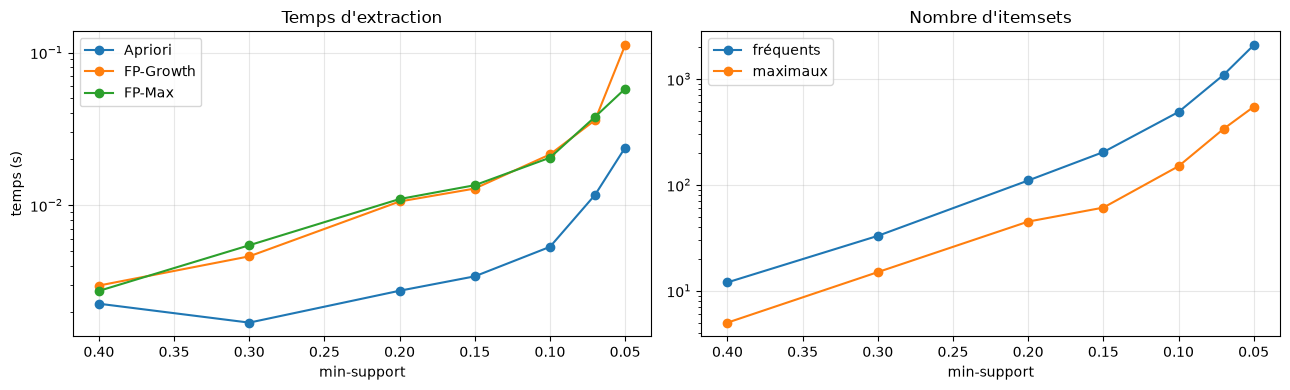

,min_support,n_itemsets,n_maximaux,t_apriori,t_fpgrowth,t_fpmax,taille_max
0,0.40,12,5,0.0023,0.0030,0.0027,3
1,0.30,33,15,0.0017,0.0046,0.0055,3
2,0.20,110,45,0.0028,0.0106,0.0110,4
3,0.15,204,61,0.0034,0.0128,0.0135,4
4,0.10,488,150,0.0053,0.0215,0.0205,5
5,0.07,1095,338,0.0117,0.0360,0.0379,5
6,0.05,2085,546,0.0238,0.1117,0.0579,6


In [18]:
perf = []
for s in [0.4, 0.3, 0.2, 0.15, 0.1, 0.07, 0.05]:
    t = time.perf_counter(); a = apriori(dfm, min_support=s, use_colnames=True); ta = time.perf_counter() - t
    t = time.perf_counter(); b = fpgrowth(dfm, min_support=s, use_colnames=True); tb = time.perf_counter() - t
    t = time.perf_counter(); m = fpmax(dfm, min_support=s, use_colnames=True); tm = time.perf_counter() - t
    perf.append(dict(min_support=s, n_itemsets=len(a), n_maximaux=len(m), t_apriori=ta, t_fpgrowth=tb, t_fpmax=tm,
                     taille_max=int(a.itemsets.apply(len).max())))
perf = pd.DataFrame(perf)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, lab in [("t_apriori", "Apriori"), ("t_fpgrowth", "FP-Growth"), ("t_fpmax", "FP-Max")]:
    axes[0].plot(perf.min_support, perf[col], "o-", label=lab)
axes[0].set_yscale("log"); axes[0].set_xlabel("min-support"); axes[0].set_ylabel("temps (s)"); axes[0].legend()
axes[0].set_title("Temps d'extraction")
axes[1].plot(perf.min_support, perf.n_itemsets, "o-", label="fréquents")
axes[1].plot(perf.min_support, perf.n_maximaux, "o-", label="maximaux")
axes[1].set_yscale("log"); axes[1].set_xlabel("min-support"); axes[1].legend(); axes[1].set_title("Nombre d'itemsets")
for a in axes: a.grid(alpha=.3); a.invert_xaxis()
plt.tight_layout(); plt.show()
perf.round(4)

**Analyse.**
- Quand le support baisse de 0,4 à 0,05, le nombre d'itemsets est multiplié par environ 170 (de 12 à 2 085), et les temps augmentent avec lui.
- **Contrairement à l'intuition, Apriori est ici plus rapide que FP-Growth.** L'implémentation d'Apriori de mlxtend est **vectorisée avec numpy** sur une matrice booléenne dense (493 × 42) qui tient en mémoire : compter un candidat revient à un produit logique de colonnes, très rapide. FP-Growth construit un arbre préfixe en **Python pur**, et ce coût fixe domine sur une base aussi petite.
- L'avantage théorique de FP-Growth (pas de génération de candidats, deux passes seulement sur la base) se manifeste sur des bases **beaucoup plus grandes** (des millions de transactions, des milliers d'items, des motifs longs). Là, Apriori doit matérialiser des ensembles de candidats énormes et relire la base à chaque niveau.
- Les itemsets **maximaux** sont environ 4 fois moins nombreux que les fréquents.

**Choix** : sur ce volume, Apriori convient très bien. On garde FP-Growth en tête pour le passage à l'échelle, et une représentation condensée (fermés ou maximaux) pour présenter les motifs. Choisir un algorithme à partir de mesures sur ses propres données, plutôt que sur sa réputation, est la démarche cohérente.

### 10.2 Qu'est-ce qui est associé au choix de la médecine générale ?

On ne garde que les règles dont le **conséquent** est `Best_spe1=généraliste`. On élimine aussi les **règles redondantes** : une règle est conservée seulement si elle améliore la confiance de toutes ses généralisations, c'est-à-dire des règles de même conséquent dont l'antécédent est un sous-ensemble du sien. C'est le critère d'*improvement* de Bayardo.

In [19]:
fim = fpgrowth(dfm, min_support=0.03, use_colnames=True)
rm = association_rules(fim, metric="confidence", min_threshold=0.0)

def target_rules(r, target, min_lift=1.2, min_conf=0.0, min_improvement=0.02):
    sub = r[(r.consequents == frozenset([target])) & (r.lift >= min_lift) & (r.confidence >= min_conf)].copy()
    conf = dict(zip(r[r.consequents == frozenset([target])].antecedents, r[r.consequents == frozenset([target])].confidence))
    base = dfm[target].mean()
    def improvement(row):
        gens = [conf.get(frozenset(g), base) for k in range(0, len(row.antecedents))
                for g in itertools.combinations(row.antecedents, k)]
        return row.confidence - max(gens)
    sub["improvement"] = sub.apply(improvement, axis=1)
    kept = sub[sub.improvement >= min_improvement]
    print(f"{target} (fréquence de base {base:.1%}) : {len(sub)} règles avec lift ≥ {min_lift}, "
          f"{len(kept)} non redondantes (improvement ≥ {min_improvement})")
    return kept.sort_values(["lift", "support"], ascending=False)

gen = target_rules(rm, "Best_spe1=généraliste")
view(gen, cols=("antecedents", "consequents", "support", "confidence", "lift", "improvement")).head(12)

Best_spe1=généraliste (fréquence de base 26.2%) : 459 règles avec lift ≥ 1.2, 136 non redondantes (improvement ≥ 0.02)


,antecedents,consequents,support,confidence,lift,improvement
0,"{Factspe_actes_medtech=2, Factspe_patients=5, Factspe_soins_spe=1}",{Best_spe1=généraliste},0.039,0.864,3.301,0.114
1,"{Factspe_gardes=5, Factspe_recherche=1, Factspe_soins_spe=1, Med_parents=Non}",{Best_spe1=généraliste},0.032,0.800,3.057,0.050
2,"{Factspe_actes_medtech=2, Factspe_soins_spe=1, Reussite_1ere_ann_med=Double}",{Best_spe1=généraliste},0.039,0.792,3.026,0.042
3,"{Factspe_actes_medtech=2, Factspe_recherche=1, Factspe_soins_spe=1}",{Best_spe1=généraliste},0.037,0.783,2.991,0.033
4,"{Factspe_gardes=5, Factspe_soins_spe=1, Med_parents=Non, Sexe_ecn=Femme}",{Best_spe1=généraliste},0.034,0.773,2.953,0.023
5,"{Classement_ecni_attendu=Q4, Factspe_patients=5, Factspe_soins_spe=1, Med_pa...",{Best_spe1=généraliste},0.032,0.762,2.912,0.048
6,"{Factspe_patients=5, Factspe_precaires=4, Factspe_soins_spe=1}",{Best_spe1=généraliste},0.032,0.762,2.912,0.133
7,"{Factspe_actes_medtech=2, Factspe_soins_spe=1}",{Best_spe1=généraliste},0.055,0.750,2.866,0.239
8,"{Factspe_gardes=5, Factspe_soins_spe=1, Med_parents=Non}",{Best_spe1=généraliste},0.043,0.750,2.866,0.083
9,"{Factspe_gardes=5, Factspe_patients=5, Factspe_recherche=1}",{Best_spe1=généraliste},0.030,0.750,2.866,0.074


**Lecture.** La fréquence de base du choix « généraliste » est de 26,2 %. Les règles retenues font apparaître des **profils** où cette proportion est **multipliée par près de 3**, avec une confiance de 75 à 86 %. Ces profils se caractérisent par :
- une **faible importance accordée aux soins spécialisés** (`Factspe_soins_spe=1`) et aux **actes techniques** (`Factspe_actes_medtech=2`) ;
- une **forte importance accordée à la relation avec les patients** (`Factspe_patients=5`).

C'est cohérent avec ce que l'on attend de la médecine générale. La règle la plus simple, `{actes_medtech=2, soins_spe=1} → généraliste`, couvre 5,5 % des étudiants avec 75 % de confiance, et a le meilleur *improvement* : c'est un bon candidat de règle « résumé ».

L'élagage par *improvement* fait passer de 459 à 136 règles, en supprimant celles qui ne font qu'ajouter un item sans apport réel.

Il s'agit d'**associations, pas de causalités** : les données sont déclaratives et l'échantillon est de taille modeste.

### 10.3 Biais de genre : règles qui concluent sur le sexe

Le TP AMIE3 posait la question du seuil de support nécessaire pour voir apparaître des règles concluant sur `Sexe_ecn=Homme`. Les hommes ne représentent que 30 % de l'échantillon. Le support d'une règle `X → Homme` est donc **au plus** de 0,30, et en pratique bien moins dès que `X` est spécifique.

In [20]:
for target in ["Sexe_ecn=Homme", "Sexe_ecn=Femme"]:
    sub = rm[(rm.consequents == frozenset([target])) & (rm.lift >= 1.15)]
    print(f"{target} : support max d'une règle de lift ≥ 1,15 = {sub.support.max():.3f} ; nombre de règles = {len(sub)}")
hom = target_rules(rm, "Sexe_ecn=Homme", min_lift=1.3)
view(hom, cols=("antecedents", "consequents", "support", "confidence", "lift", "improvement")).head(8)

Sexe_ecn=Homme : support max d'une règle de lift ≥ 1,15 = 0.120 ; nombre de règles = 129
Sexe_ecn=Femme : support max d'une règle de lift ≥ 1,15 = 0.181 ; nombre de règles = 588
Sexe_ecn=Homme (fréquence de base 29.8%) : 93 règles avec lift ≥ 1.3, 38 non redondantes (improvement ≥ 0.02)


,antecedents,consequents,support,confidence,lift,improvement
0,"{Classement_ecni_attendu=Q1, Factspe_soins_spe=4}",{Sexe_ecn=Homme},0.037,0.750,2.515,0.270
1,"{Classement_ecni_attendu=Q1, Factspe_patients=3, Reussite_1ere_ann_med=Reussit}",{Sexe_ecn=Homme},0.032,0.640,2.146,0.126
2,"{Classement_ecni_attendu=Q1, Factspe_actes_medtech=5}",{Sexe_ecn=Homme},0.037,0.581,1.947,0.101
3,"{Classement_ecni_attendu=Q1, Factspe_precaires=2, Reussite_1ere_ann_med=Reus...",{Sexe_ecn=Homme},0.034,0.567,1.900,0.053
4,"{Factspe_soins_spe=4, Reussite_1ere_ann_med=Reussit}",{Sexe_ecn=Homme},0.030,0.556,1.863,0.130
5,"{Classement_ecni_attendu=Q1, Factspe_soins_spe=3}",{Sexe_ecn=Homme},0.032,0.533,1.789,0.054
6,"{Best_spe1=autre, Classement_ecni_attendu=Q1, Factspe_precaires=3}",{Sexe_ecn=Homme},0.039,0.528,1.770,0.028
7,"{Classement_ecni_attendu=Q1, Reussite_1ere_ann_med=Reussit}",{Sexe_ecn=Homme},0.077,0.514,1.722,0.034


In [21]:
# Seuil de support nécessaire pour voir au moins une règle « → Homme » informative (lift ≥ 1,3)
for s in [0.2, 0.15, 0.1, 0.07, 0.05, 0.03]:
    f = fpgrowth(dfm, min_support=s, use_colnames=True)
    r = association_rules(f, metric="lift", min_threshold=1.3)
    n_h = int((r.consequents == frozenset(["Sexe_ecn=Homme"])).sum())
    print(f"min_support = {s:<5} → {n_h:3d} règle(s) concluant sur Homme avec un lift ≥ 1,3")

min_support = 0.2   →   0 règle(s) concluant sur Homme avec un lift ≥ 1,3
min_support = 0.15  →   0 règle(s) concluant sur Homme avec un lift ≥ 1,3
min_support = 0.1   →   2 règle(s) concluant sur Homme avec un lift ≥ 1,3
min_support = 0.07  →   6 règle(s) concluant sur Homme avec un lift ≥ 1,3


min_support = 0.05  →  20 règle(s) concluant sur Homme avec un lift ≥ 1,3


min_support = 0.03  →  93 règle(s) concluant sur Homme avec un lift ≥ 1,3


**Analyse.**
- **Aucune** règle informative ne conclut sur `Homme` tant que le support minimal reste à 0,15 ou plus. Il faut descendre à **0,1** pour en voir 2, et à 0,05 pour en voir 20. C'est la limite classique du cadre support/confiance : un seuil de support global **efface les sous-populations minoritaires**.
- Sur le fond, l'antécédent récurrent des règles `→ Homme` est `Classement_ecni_attendu=Q1` : les hommes de l'échantillon **s'attendent plus souvent à être dans le premier quartile**. Avec `Reussite_1ere_ann_med=Reussit`, la proportion d'hommes passe de 30 % à 51 %. Ce pourrait être un signe de **différence de confiance en soi déclarée** selon le genre, un résultat connu en sociologie de l'éducation, mais à confirmer sur ces données.

Deux remèdes cohérents :
1. raisonner en **support relatif au conséquent**, c'est-à-dire le *head coverage* $\text{supp}(X\cup Y)/\text{supp}(Y)$ utilisé par AMIE, plutôt qu'en support absolu ;
2. fixer un seuil de support par conséquent (extraction ciblée).

Ces associations sont des **pistes** d'étude du biais de genre. Il faudrait les valider statistiquement (par exemple avec un test du χ² et une correction pour tests multiples, puisque des centaines de règles sont examinées), car sur 493 individus une règle de support 0,03 ne concerne qu'une quinzaine de personnes.

<a id="11"></a>
## 11. Conclusion

| Question | Réponse ou choix argumenté |
|---|---|
| Seuils (Grocery) | support de 0,1 pour explorer, 0,2 pour présenter ; confiance de 0,6 à 0,7 ; **tri par lift** |
| Mesure d'intérêt | la confiance seule est trompeuse (conséquents fréquents) ; le **lift** corrige ce biais ; le leverage mesure l'impact |
| Algorithme | Apriori et FP-Growth sont exacts et **identiques** en résultat ; ici, Apriori (vectorisé) est plus rapide ; FP-Growth est à réserver aux très grandes bases ; fermés et maximaux servent à condenser |
| Règles sûres | elles sont à interpréter avec leur support : « 100 % sur 2 paniers » est fragile |
| Q8 ($X\subset Z$) | $s' \le s$ ; aucune relation générale sur $c'$, vérifiée sur les données |
| Q9 ($X\cup a \to Y\cup a$) | $s' \le s$, $c' = \text{conf}(X\cup a\to Y)$ : règle **redondante**, d'où $X\cap Y=\emptyset$ |
| Données réelles | profil « généraliste » : faible attrait pour la technique et forte importance de la relation patient (lift ≈ 3) ; l'élagage par *improvement* fait passer de 459 à 136 règles ; la classe minoritaire `Homme` n'apparaît qu'avec un support ≤ 0,1, d'où l'intérêt d'un support relatif (head coverage) |

**Compétences mobilisées** : Python, pandas, mlxtend, implémentation algorithmique (Apriori), mesures d'intérêt, analyse de sensibilité, interprétation métier et esprit critique sur les résultats.